# 05 — KNN (K-Nearest Neighbors)

Predict from the K most similar examples. The same idea powers semantic search and RAG retrieval.

## What's in this notebook

- 1\. What is KNN?
- 2\. How a prediction works
- 3\. Distance metrics
- 4\. Feature scaling: the #1 KNN mistake
- 5\. Choosing K
- 6\. Tuning K, weights and metric together
- 7\. KNN regression
- 8\. Curse of dimensionality
- 9\. KNN = vector search (the GenAI link)
- 10\. Key parameters
- 11\. When to use KNN
- 12\. Interview questions
- 13\. In my own words

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, fetch_20newsgroups
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

# NumPy 2.2 + Apple Accelerate prints harmless "encountered in matmul" RuntimeWarnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

# 1. WHAT IS KNN?

To predict a new point, KNN finds the **K training points closest to it** and:
- **classification:** takes a majority vote of their labels
- **regression:** takes the average of their values

It learns no weights. Training just stores the data; all the work happens at prediction time.
That's why it's called **lazy learning**.

Example: should we expect this customer to churn? Look at the 5 most similar customers:

| Neighbour | Churned? |
|---|---|
| 1 | yes |
| 2 | no |
| 3 | yes |
| 4 | yes |
| 5 | no |

3 votes yes, 2 no → predict **churn**.

# 2. HOW A PREDICTION WORKS

1. Compute the distance from the new point to **every** training point
2. Keep the K closest
3. Vote (classification) or average (regression)

Cost:
- **training:** almost free (store the data)
- **prediction:** one distance per training point, O(n · d) per query (n points, d features)

So KNN is slow on large datasets unless we use a search index (section 9).

# 3. DISTANCE METRICS

| Metric | Formula | Use when |
|---|---|---|
| Euclidean | √Σ (aᵢ − bᵢ)² | default; continuous features on similar scales |
| Manhattan | Σ \|aᵢ − bᵢ\| | grid-like data; less affected by one big difference |
| Cosine distance | 1 − (a · b) / (‖a‖ ‖b‖) | only the **direction** matters: text, embeddings |

scikit-learn's default is `metric="minkowski", p=2`, which is Euclidean (`p=1` is Manhattan).

In [2]:
a = np.array([1.0, 2.0])
b = np.array([2.0, 4.0])          # same direction as a, twice as long

euclidean = np.sqrt(np.sum((a - b) ** 2))
manhattan = np.sum(np.abs(a - b))
cosine_distance = 1 - a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

print(f"Euclidean = {euclidean:.3f}   Manhattan = {manhattan:.3f}   Cosine distance = {cosine_distance:.3f}")

Euclidean = 2.236   Manhattan = 3.000   Cosine distance = 0.000


Cosine distance is 0 because a and b point the same way. Length is ignored.
That's exactly what we want for embeddings, where the direction carries the meaning.

# 4. FEATURE SCALING: THE #1 KNN MISTAKE

Distance adds up the differences of all features. If one feature has a much bigger range,
it dominates the distance and the other features barely count.

The wine dataset shows it well: `proline` is in the hundreds/thousands, `hue` is around 1.

In [3]:
X, y = load_wine(return_X_y=True, as_frame=True)
print(X[["proline", "magnesium", "alcohol", "hue"]].describe().loc[["min", "max"]].round(2))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)

print(f"\nAccuracy without scaling: {raw.score(X_test, y_test):.3f}")
print(f"Accuracy with scaling:    {scaled.score(X_test, y_test):.3f}")

     proline  magnesium  alcohol   hue
min    278.0       70.0    11.03  0.48
max   1680.0      162.0    14.83  1.71

Accuracy without scaling: 0.722
Accuracy with scaling:    0.944


Scaling lifts accuracy from **0.72 to 0.94**. Without it, `proline` (range 278 to 1,680) decides almost every distance on its own.

Always put the scaler and KNN in **one Pipeline**, so the scaler is fit on training data only.

# 5. CHOOSING K

- **Small K** (e.g. 1): follows every noisy point → **overfitting** (high variance)
- **Large K**: averages over too many points, including other classes → **underfitting** (high bias)
- Pick K with **cross-validation**. For two classes, use an **odd** K to avoid ties.

best K = 12, CV accuracy = 0.968   (K = 1: 0.951)


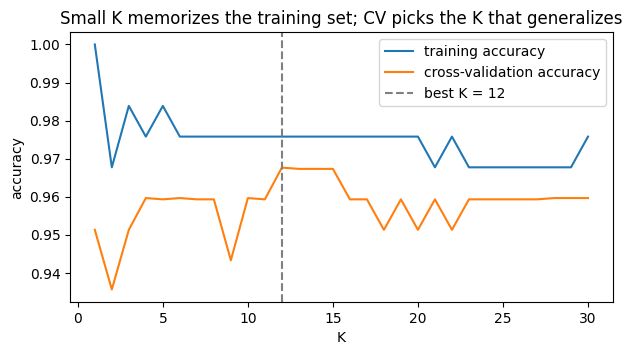

In [4]:
ks = range(1, 31)
train_acc, cv_acc = [], []
for k in ks:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    train_acc.append(model.fit(X_train, y_train).score(X_train, y_train))
    cv_acc.append(cross_val_score(model, X_train, y_train, cv=5).mean())

best_k = list(ks)[int(np.argmax(cv_acc))]
print(f"best K = {best_k}, CV accuracy = {max(cv_acc):.3f}   (K = 1: {cv_acc[0]:.3f})")
plt.figure(figsize=(7, 3.5))
plt.plot(ks, train_acc, label="training accuracy")
plt.plot(ks, cv_acc, label="cross-validation accuracy")
plt.axvline(best_k, color="gray", linestyle="--", label=f"best K = {best_k}")
plt.xlabel("K")
plt.ylabel("accuracy")
plt.legend()
plt.title("Small K memorizes the training set; CV picks the K that generalizes")
plt.show()

At K = 1 training accuracy is 1.0, because every point is its own nearest neighbour. That says nothing about new data.
Look at the cross-validation line instead. On this dataset it is almost flat: every K from 4 to 30 scores within 1 point of the best (K = 12, CV accuracy 0.968).
That's common. The exact K matters much less than scaling, so pick a sensible K with CV and move on.

# 6. TUNING K, WEIGHTS AND METRIC TOGETHER

- `weights="uniform"`: every neighbour gets one vote
- `weights="distance"`: closer neighbours count more (useful when K is large)

In [5]:
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
grid = GridSearchCV(pipe, {
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 11, 15],
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__metric": ["euclidean", "manhattan"],
}, cv=5).fit(X_train, y_train)

results = pd.DataFrame(grid.cv_results_).rename(columns=lambda c: c.replace("param_kneighborsclassifier__", ""))
top = results[["n_neighbors", "weights", "metric", "mean_test_score"]].sort_values("mean_test_score", ascending=False)
print(top.head(6).round(3).to_string(index=False))
print(f"\nTest accuracy with the best settings: {grid.score(X_test, y_test):.3f}")

 n_neighbors  weights    metric  mean_test_score
          11 distance manhattan            0.975
          11  uniform manhattan            0.975
           7 distance manhattan            0.975
           7  uniform manhattan            0.975
           5 distance manhattan            0.975
           5  uniform manhattan            0.975

Test accuracy with the best settings: 0.981


Several settings tie at the top (CV ≈ 0.975, Manhattan slightly ahead).
Once the data is scaled, these choices move the score by a point or two. Scaling moved it by more than 20.

# 7. KNN REGRESSION

Same idea, but the prediction is the **average** of the K neighbours' values.
The result is a step-like curve: KNN can't predict outside the range of values it has seen.

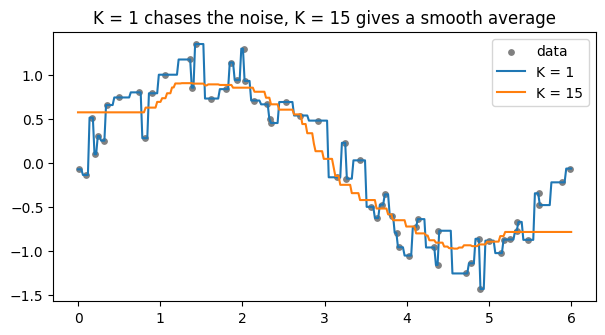

In [6]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 6, 60)).reshape(-1, 1)
y_reg = np.sin(x).ravel() + rng.normal(0, 0.2, 60)
grid_x = np.linspace(0, 6, 300).reshape(-1, 1)

plt.figure(figsize=(7, 3.5))
plt.scatter(x, y_reg, s=15, color="gray", label="data")
for k in (1, 15):
    pred = KNeighborsRegressor(n_neighbors=k).fit(x, y_reg).predict(grid_x)
    plt.plot(grid_x, pred, label=f"K = {k}")
plt.legend()
plt.title("K = 1 chases the noise, K = 15 gives a smooth average")
plt.show()

# 8. CURSE OF DIMENSIONALITY

In many dimensions, **all points end up almost equally far apart**, so "nearest" stops meaning much.
Below: random points, and the ratio between the nearest and the farthest distance from one point.

In [7]:
rng = np.random.default_rng(42)
rows = []
for d in [2, 10, 100, 1000]:
    points = rng.uniform(size=(1000, d))
    dist = np.linalg.norm(points[1:] - points[0], axis=1)
    rows.append({"dimensions": d, "nearest / farthest distance": round(dist.min() / dist.max(), 3)})
pd.DataFrame(rows)

,dimensions,nearest / farthest distance
0,2,0.010
1,10,0.317
2,100,0.715
3,1000,0.890


In 2 dimensions the nearest point is about 100× closer than the farthest (ratio 0.01).
In 1,000 dimensions the ratio is 0.89: the nearest point is barely closer than the farthest one.

Fixes: keep only useful features, reduce dimensions (PCA), or use **learned embeddings**,
where the model has been trained so that distance means similarity.

# 9. KNN = VECTOR SEARCH (THE GENAI LINK)

Semantic search and the retrieval step of RAG are KNN:

1. turn every document into a vector (an **embedding**)
2. turn the question into a vector
3. return the K documents whose vectors are closest (usually **cosine similarity**)

If vectors are normalized to length 1, cosine similarity is just the **dot product**, which is very fast to compute.

Below, the "embeddings" are 100-dimensional vectors made from TF-IDF + SVD (a classic method called LSA).
Real systems use a neural embedding model, but the search step is the same.

In [8]:
categories = ["comp.graphics", "rec.sport.hockey", "sci.med", "sci.space"]
posts = fetch_20newsgroups(subset="train", categories=categories, remove=("headers", "footers", "quotes"), random_state=42)
topics = [name.split(".")[-1] for name in posts.target_names]

tfidf = TfidfVectorizer(stop_words="english", min_df=2)
svd = TruncatedSVD(n_components=100, random_state=42)
doc_vectors = normalize(svd.fit_transform(tfidf.fit_transform(posts.data)))      # one unit-length vector per post


def search(query, k=3):
    q = normalize(svd.transform(tfidf.transform([query])))
    scores = doc_vectors @ q.ravel()                       # dot product = cosine similarity here
    top = np.argsort(scores)[::-1][:k]
    return pd.DataFrame({"cosine": scores[top].round(3),
                         "topic": [topics[posts.target[i]] for i in top],
                         "post": [" ".join(posts.data[i].split())[:80] for i in top]})


search("rocket launch to the moon")

,cosine,topic,post
0,0.739,space,"In fact, you probably want to avoid US Governm..."
1,0.710,space,Why use a ground launch pad. It is entirely po...
2,0.669,space,Suppose the Soviets had managed to get their m...


In [9]:
search("treatment for high blood pressure")

,cosine,topic,post
0,0.776,med,Elevated levels of Glu and Asp in the blood ar...
1,0.758,med,The term arrhythmia is usually used to encompa...
2,0.743,med,"Serum, actually, but plasma numbers are the sa..."


In [10]:
# The same search with scikit-learn's NearestNeighbors (brute force = compare with every vector)
index = NearestNeighbors(n_neighbors=3, metric="cosine", algorithm="brute").fit(doc_vectors)
q = normalize(svd.transform(tfidf.transform(["rocket launch to the moon"])))
distances, ids = index.kneighbors(q)
print("same top-3 posts:", list(ids[0]) == list(np.argsort(doc_vectors @ q.ravel())[::-1][:3]))

start = time.perf_counter()
for _ in range(100):
    index.kneighbors(q)
print(f"brute-force search over {len(doc_vectors):,} vectors: {(time.perf_counter() - start) * 10:.2f} ms per query")

same top-3 posts: True
brute-force search over 2,371 vectors: 0.68 ms per query


Brute force is fine for thousands of vectors, but its cost grows with every vector added (O(n · d) per query).
For millions of vectors, systems use **approximate nearest neighbour (ANN)** indexes, which give up a little accuracy for a lot of speed:

| Index | Idea |
|---|---|
| **HNSW** | a graph of neighbours; search walks the graph toward the query |
| **IVF** | cluster the vectors with **K-Means**; search only the clusters nearest the query |
| **PQ** (product quantization) | compress vectors so more fit in memory |

They are available in FAISS and in vector databases (pgvector, Qdrant, Milvus, Pinecone).
scikit-learn's KD-tree and ball-tree also speed up KNN, but only in low dimensions (roughly under 20).

# 10. KEY PARAMETERS

| Parameter | Default | What it does |
|---|---|---|
| `n_neighbors` | 5 | K. Small = flexible (overfit risk), large = smooth (underfit risk) |
| `weights` | `"uniform"` | `"distance"` gives closer neighbours more say |
| `metric` | `"minkowski"` (p=2) | Euclidean; `"manhattan"`, `"cosine"` are common alternatives |
| `algorithm` | `"auto"` | `"kd_tree"` / `"ball_tree"` (fast in low dimensions) or `"brute"` |

# 11. WHEN TO USE KNN

| Good | Bad |
|---|---|
| No training; adding new data is instant | Prediction is slow and needs all data in memory |
| Works for any number of classes, any boundary shape | Needs feature scaling |
| Easy to explain ("these 5 similar cases") | Weak in high dimensions on raw features |
| Great with good embeddings (search, recommendations) | Irrelevant features and class imbalance hurt the vote |

Use it for small to medium tabular data, as a quick baseline, and, with an ANN index, for search over embeddings.

**KNN vs K-Means** (often confused):

| | KNN | K-Means |
|---|---|---|
| Type | supervised (needs labels) | unsupervised (no labels) |
| K means | number of neighbours | number of clusters |
| Output | a prediction for one point | a cluster for every point |

# 12. INTERVIEW QUESTIONS

### Q1. Explain KNN in 30 seconds.
KNN predicts from the K closest training examples: majority vote for classification, average for regression.
It has no training phase, so prediction is the expensive part. Features must be scaled, K is chosen with
cross-validation, and the same nearest-neighbour idea is how vector search and RAG retrieval work.

### Q2. Why is KNN called lazy?
It doesn't learn anything at training time; it just stores the data and does the work when predicting.

### Q3. How do you choose K?
Cross-validation. Small K overfits (high variance), large K underfits (high bias). Use an odd K for two classes.

### Q4. Why does KNN need feature scaling?
Distance sums differences across features, so the feature with the largest range dominates. Scale in a Pipeline.

### Q5. Which distance metric would you use?
Euclidean by default, Manhattan for grid-like data, cosine for text and embeddings (direction, not length).

### Q6. What is the curse of dimensionality?
In high dimensions all points become almost equally far apart, so nearest neighbours stop being meaningful.

### Q7. What is the time complexity?
Training is almost free. A brute-force prediction is O(n · d) per query. KD-trees and ball-trees help only in low dimensions.

### Q8. How do you search millions of vectors fast?
Approximate nearest neighbour indexes such as HNSW or IVF (built with K-Means), in FAISS or a vector database.
They trade a little recall for a big speed-up.

### Q9. How does class imbalance affect KNN?
The majority class wins most votes. Use distance weighting, rebalance the data, or pick another model.

### Q10. KNN vs K-Means?
KNN is supervised and predicts from neighbours; K-Means is unsupervised and groups the data into K clusters.

# 13. IN MY OWN WORDS

Write this from memory, without looking above:

- What KNN does:
- Why scaling matters:
- How I would choose K:
- How KNN connects to RAG: